In [ ]:
# Part 1: Data Analysis and Preprocessing
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

apartments_df = pd.read_csv('data/apartments_for_rent_classified_10K.csv',sep=';',encoding='cp1252')
apartments_df['time'] = pd.to_datetime(apartments_df['time'],unit='s',errors='coerce')

data_types = pd.DataFrame({'Feature': apartments_df.columns,'Data Type': apartments_df.dtypes.astype(str).values})
display(data_types)

continuous_features = apartments_df.select_dtypes(include='number').columns.tolist()
continuous_features = [col for col in continuous_features if col != 'id']
print("Continuous features:")
print(continuous_features)

categorical_features = apartments_df.select_dtypes(include=['object', 'string', 'category', 'bool']).columns.tolist()
print("\nCategorical features:")
print(categorical_features)

,Feature,Data Type
0,id,int64
1,category,str
2,title,str
3,body,str
4,amenities,str
5,bathrooms,float64
6,bedrooms,float64
7,currency,str
8,fee,str
9,has_photo,str


Continuous features:
['bathrooms', 'bedrooms', 'price', 'square_feet', 'latitude', 'longitude']

Categorical features:
['category', 'title', 'body', 'amenities', 'currency', 'fee', 'has_photo', 'pets_allowed', 'price_display', 'price_type', 'address', 'cityname', 'state', 'source']


In [ ]:
# Part 1: Data quality report for continuous features 
continuous_report = pd.DataFrame(index=continuous_features)

# Table for numerical features
continuous_report.index.name = 'Feature'
# The number of non-missing values for each feature 
continuous_report['Count'] = (apartments_df[continuous_features].count())
# The percentage of missing values for each feature 
continuous_report['% Miss'] = (apartments_df[continuous_features].isna().mean() * 100).round(2)
# Cardinality represents the number of unique values
continuous_report['Card.'] = (apartments_df[continuous_features].nunique())
# The min 
continuous_report['Min'] = (apartments_df[continuous_features].min())
# Q1 
continuous_report['Q1'] = (apartments_df[continuous_features].quantile(0.25))
# Mean
continuous_report['Mean'] = (apartments_df[continuous_features].mean())
# Median
continuous_report['Median'] = (apartments_df[continuous_features].median())
# Q3
continuous_report['Q3'] = (apartments_df[continuous_features].quantile(0.75))
# The max
continuous_report['Max'] = (apartments_df[continuous_features].max())
# The standard deviation 
continuous_report['Std. Dev.'] = (apartments_df[continuous_features].std())

display(continuous_report.round(3))

,Count,% Miss,Card.,Min,Q1,Mean,Median,Q3,Max,Std. Dev.
Feature,,,,,,,,,,
bathrooms,9966,0.34,14,1.000,1.000,1.381,1.000,2.00,8.500,0.615
bedrooms,9993,0.07,10,0.000,1.000,1.744,2.000,2.00,9.000,0.942
price,10000,0.00,1725,200.000,949.000,1486.278,1270.000,1695.00,52500.000,1076.508
square_feet,10000,0.00,1738,101.000,649.000,945.810,802.000,1100.00,40000.000,655.756
latitude,9990,0.10,2395,21.316,33.680,37.695,38.810,41.35,61.594,5.496
longitude,9990,0.10,2392,-158.022,-101.302,-94.652,-93.652,-82.21,-70.192,15.760


In [ ]:
# Part 1: Categorical Feature Analysis
categorical_stats = []

# Analyze each categorical column
for col in categorical_features:
    values = apartments_df[col].dropna()
    freq = values.value_counts()

    categorical_stats.append({
        'Feature': col,
        'Count': values.count(),
        '% Miss': round(apartments_df[col].isna().mean() * 100, 2),
        'Card.': values.nunique(),
        'Mode': freq.index[0] if len(freq) > 0 else np.nan,
        'Mode Freq': freq.iloc[0] if len(freq) > 0 else 0,
        'Mode %': round(freq.iloc[0] / len(values) * 100, 2) if len(freq) > 0 else 0,
        '2nd Mode': freq.index[1] if len(freq) > 1 else np.nan,
        '2nd Mode Freq': freq.iloc[1] if len(freq) > 1 else 0,
        '2nd Mode %': round(freq.iloc[1] / len(values) * 100, 2) if len(freq) > 1 else 0
    })
 
categorical_report = pd.DataFrame(categorical_stats).set_index('Feature')

display(categorical_report.round(2))
    

,Count,% Miss,Card.,Mode,Mode Freq,Mode %,2nd Mode,2nd Mode Freq,2nd Mode %
Feature,,,,,,,,,
category,10000,0.00,3,housing/rent/apartment,9996,99.96,housing/rent/home,2,0.02
title,10000,0.00,9350,Apartment in great location,40,0.40,Super Cute! Apartment for Rent!,32,0.32
body,10000,0.00,9961,"When searching for a pet-friendly One-, Two- a...",6,0.06,"If you re looking to lease your new home, you ...",4,0.04
amenities,6451,35.49,2254,Parking,229,3.55,"Dishwasher,Refrigerator",225,3.49
currency,10000,0.00,1,USD,10000,100.00,NaN,0,0.00
fee,10000,0.00,1,No,10000,100.00,NaN,0,0.00
has_photo,10000,0.00,3,Thumbnail,8907,89.07,Yes,909,9.09
pets_allowed,5837,41.63,3,"Cats,Dogs",5228,89.57,Cats,485,8.31
price_display,10000,0.00,1726,"$1,350",86,0.86,"$1,250",81,0.81


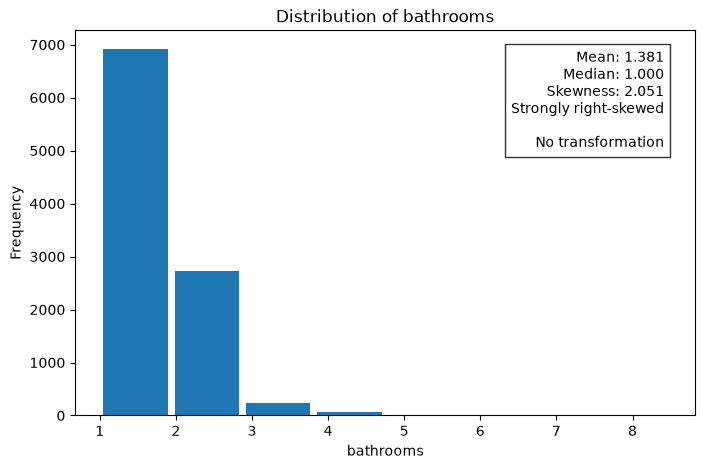

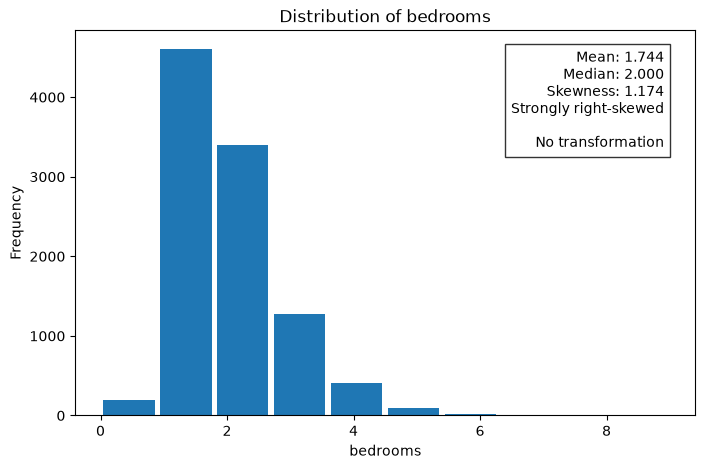

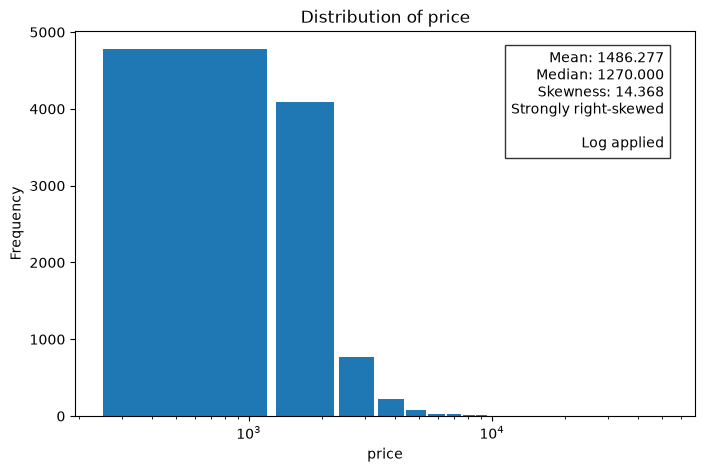

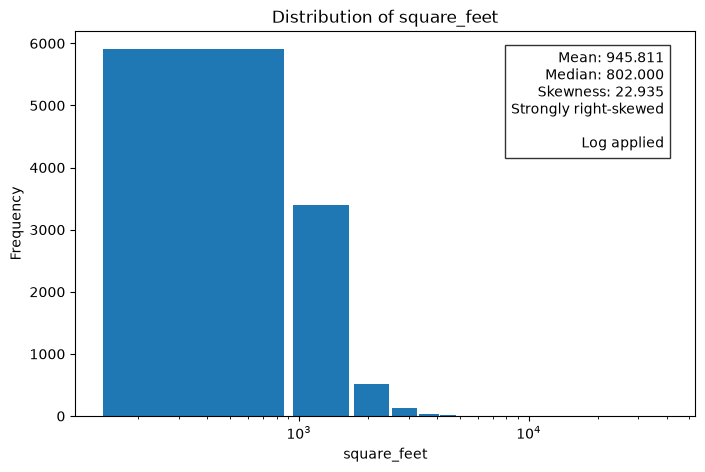

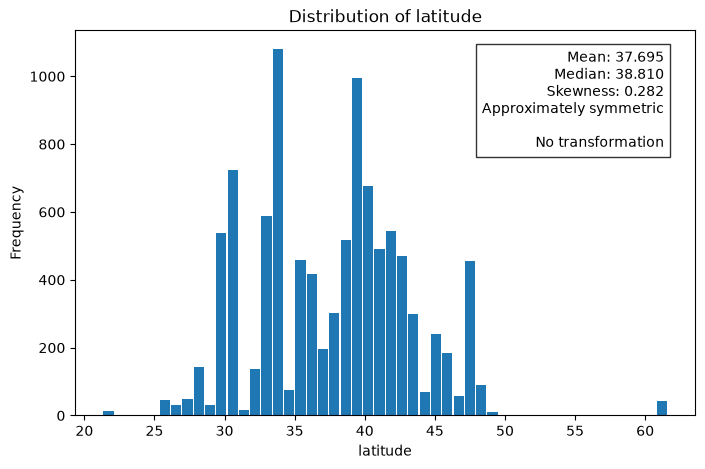

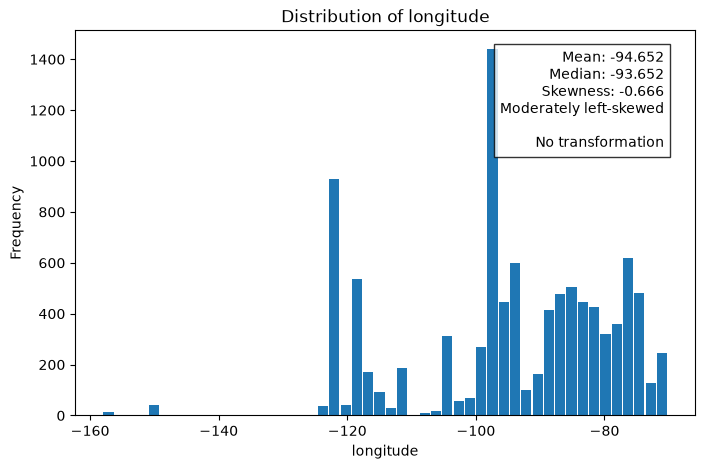

In [ ]:
# Part 1: Distribution Analysis of Continuous Features
apartments_transformed = apartments_df.copy()

for feature in continuous_features:
    data = apartments_df[feature].dropna()
    mean, median, skew = data.mean(), data.median(), data.skew()

    # The distribution based on skewness
    if skew < -1:
        interpretation = "Strongly left-skewed"
    elif skew < -0.5:
        interpretation = "Moderately left-skewed"
    elif skew < 0:
        interpretation = "Slightly left-skewed"
    elif skew < 0.5:
        interpretation = "Approximately symmetric"
    elif skew < 1:
        interpretation = "Moderately right-skewed"
    else:
        interpretation = "Strongly right-skewed"

    # The log transformation to highly skewed non-negative features
    apply_log = (
        skew >= 1
        and feature not in ['bedrooms', 'bathrooms']
        and (data >= 0).all()
    )

    if apply_log:
        apartments_transformed[feature] = np.log1p(apartments_df[feature])

    transformation = "Log applied" if apply_log else "No transformation"

    # The distribution graphs
    bins = max(1, int(data.max() - data.min() + 1)) if feature in ['bedrooms', 'bathrooms'] else 50

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.hist(data, bins=bins, rwidth=0.9)

    ax.set(
        title=f'Distribution of {feature}',
        xlabel=feature,
        ylabel='Frequency'
    )

    if feature in ['price', 'square_feet'] and (data > 0).all():
        ax.set_xscale('log')

    stats = (
        f'Mean: {mean:.3f}\n'
        f'Median: {median:.3f}\n'
        f'Skewness: {skew:.3f}\n'
        f'{interpretation}\n\n'
        f'{transformation}'
    )

    ax.text(
        0.95, 0.95, stats,
        transform=ax.transAxes,
        ha='right', va='top',
        bbox=dict(facecolor='white', alpha=0.8)
    )

    ax.grid(False)
    plt.show()

C:\Users\ASUS\AppData\Local\Temp\ipykernel_16564\2668988745.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False)


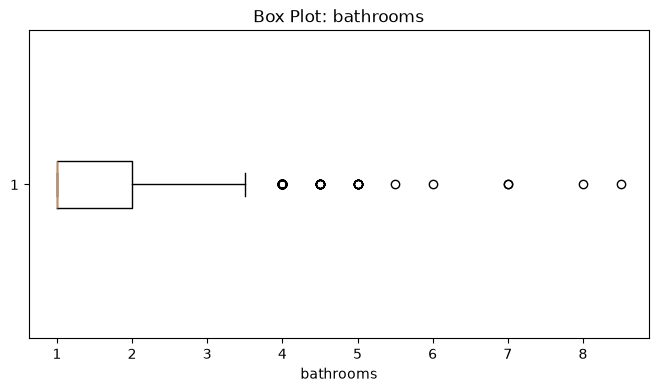

C:\Users\ASUS\AppData\Local\Temp\ipykernel_16564\2668988745.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False)


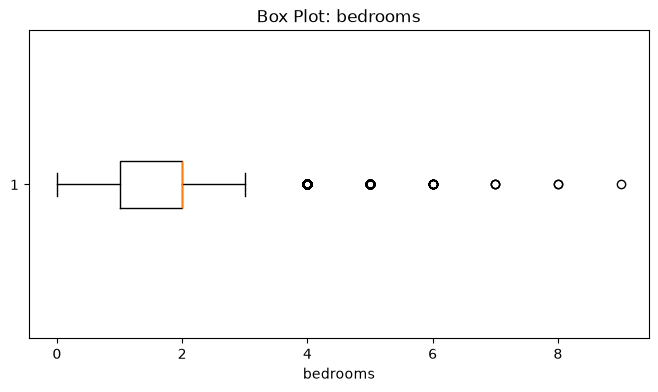

C:\Users\ASUS\AppData\Local\Temp\ipykernel_16564\2668988745.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False)


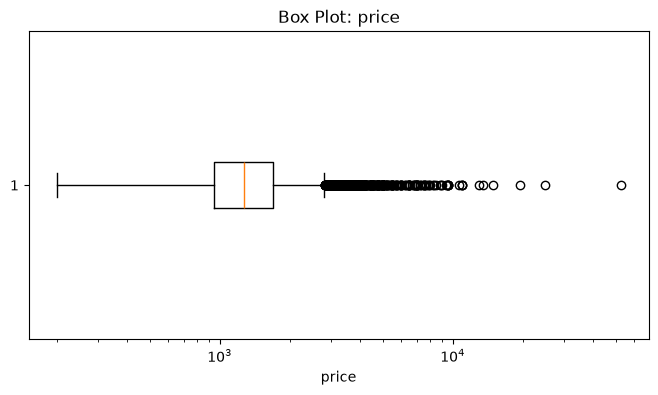

C:\Users\ASUS\AppData\Local\Temp\ipykernel_16564\2668988745.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False)


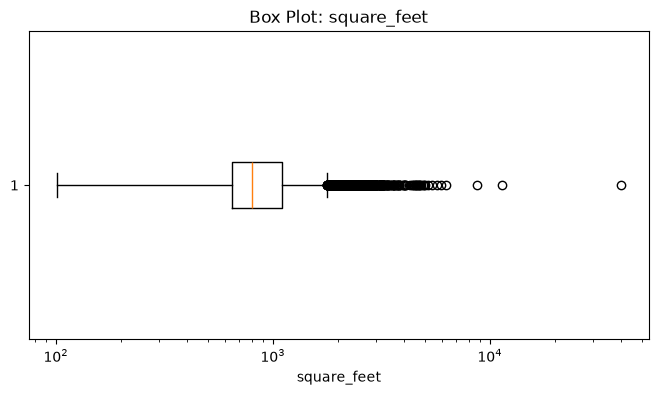

C:\Users\ASUS\AppData\Local\Temp\ipykernel_16564\2668988745.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False)


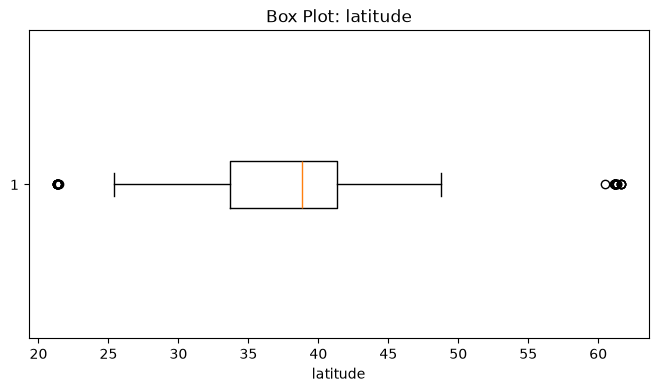

C:\Users\ASUS\AppData\Local\Temp\ipykernel_16564\2668988745.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False)


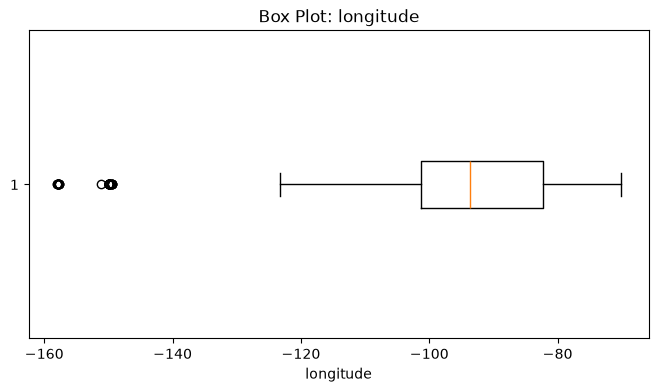

In [ ]:
# Part 1: Box Plots for Continuous Features
for feature in continuous_features:
    values = apartments_df[feature].dropna()
    # The horizontal box plot
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.boxplot(values, vert=False)

    ax.set(
        title=f'Box Plot: {feature}',
        xlabel=feature
    )

    # The logarithmic scale for features with large ranges
    if feature in ['price', 'square_feet'] and (values > 0).all():
        ax.set_xscale('log')

    ax.grid(False)
    plt.show()

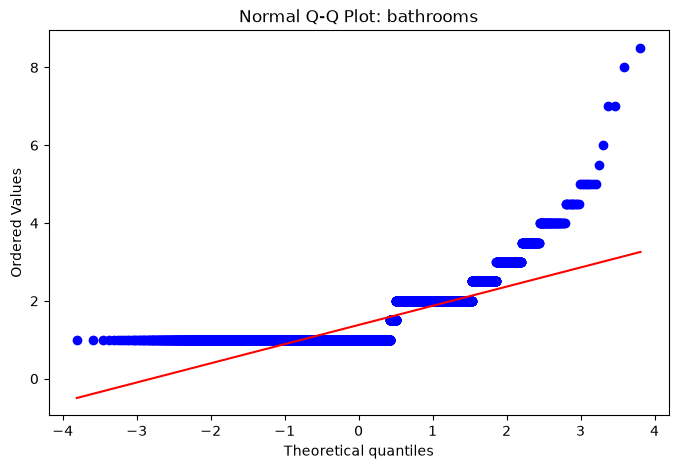

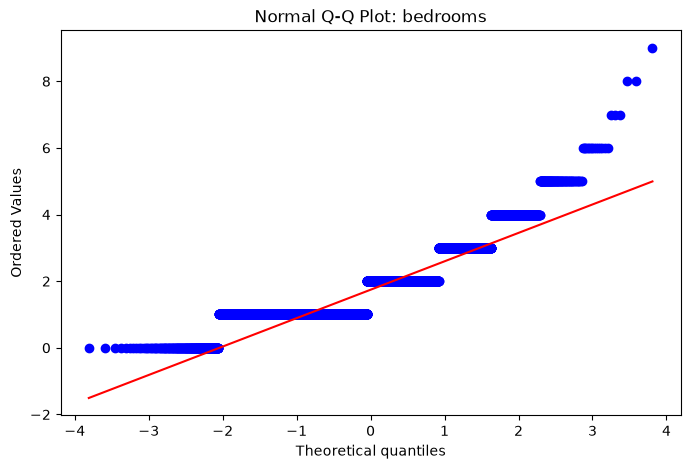

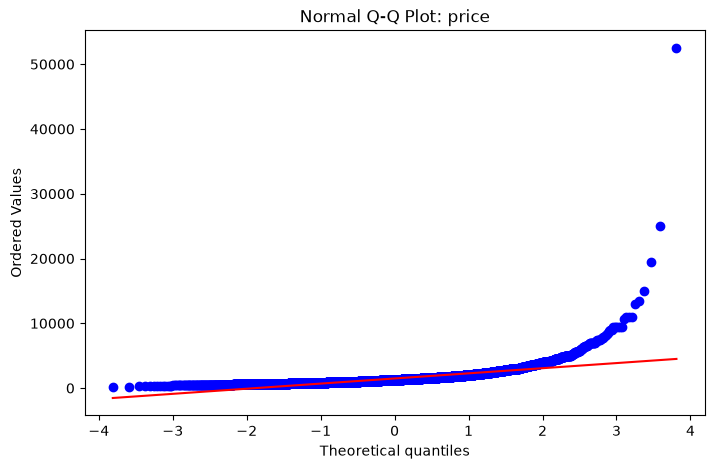

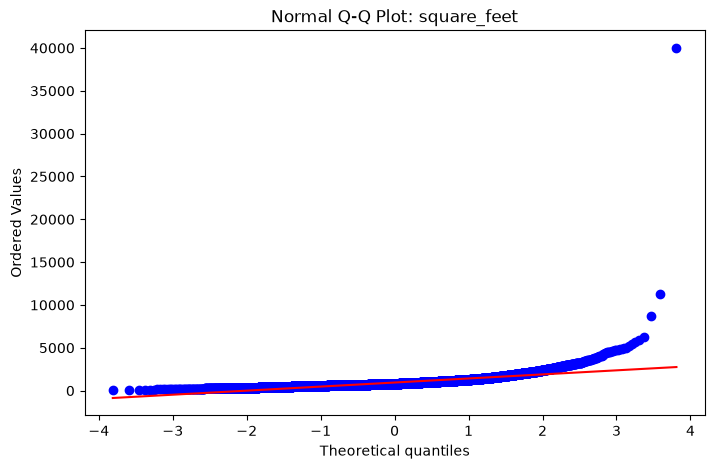

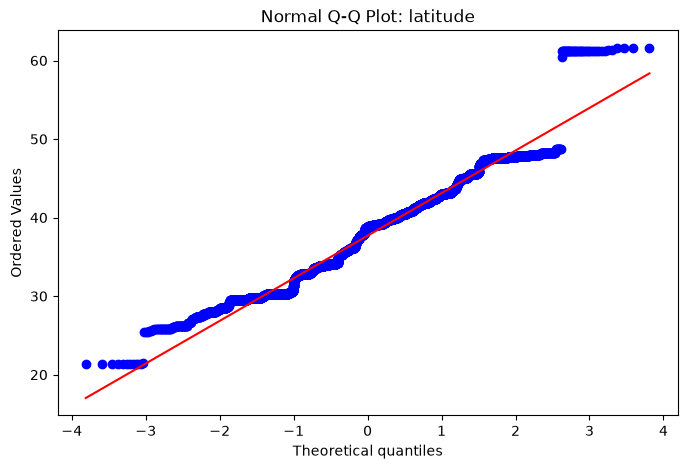

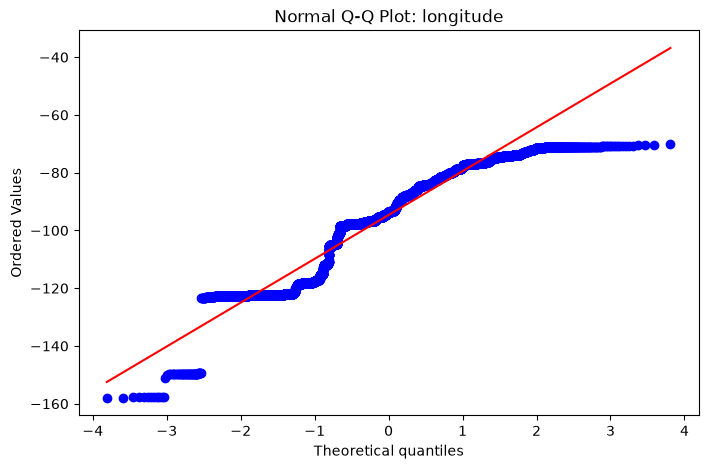

In [ ]:
# Part 1: Normality Assessment using Q-Q Plots
from scipy import stats
for feature in continuous_features:
    values = apartments_df[feature].dropna()

    # Comparison between data quantiles and a normal distribution
    fig, ax = plt.subplots(figsize=(8, 5))
    stats.probplot(values, dist='norm', plot=ax)

    ax.set(title=f'Normal Q-Q Plot: {feature}')
    ax.grid(False)

    plt.show()

# Interpretation:
# Points following the reference line suggest an approximately normal distribution.
# Large deviations indicate skewness, outliers, or heavy tails.
# Price and square_feet are highly skewed, while bedrooms and bathrooms
# also deviate from normality due to their discrete distributions.
# Latitude and longitude may show smaller deviations but are not fully normal.
#


In [ ]:
# Part 1: Shapiro-Wilk Normality Test
from scipy.stats import shapiro
results = []

for feature in continuous_features:
    values = apartments_df[feature].dropna()
    sample = values.sample(n=min(5000, len(values)), random_state=42)

    w_stat, p_val = shapiro(sample)

    results.append({
        'Feature': feature,
        'W statistic': w_stat,
        'p-value': p_val,
        'Normal': 'Yes' if p_val >= 0.05 else 'No'
    })

normality_report = pd.DataFrame(results)
display(normality_report.round(5))

# Interpretation:
# H0: The feature follows a normal distribution.
# If p < 0.05, we reject H0 and conclude that normality is unlikely.
# Small p-values indicate deviations from normality.
# Results should also be compared with histograms and Q-Q plots.

,Feature,W statistic,p-value,Normal
0,bathrooms,0.63412,0.0,No
1,bedrooms,0.81694,0.0,No
2,price,0.44984,0.0,No
3,square_feet,0.40644,0.0,No
4,latitude,0.97131,0.0,No
5,longitude,0.92644,0.0,No


In [ ]:
# Part 1: Standardization of Continuous Features
from sklearn.preprocessing import StandardScaler
# The common range
scaler = StandardScaler()
apartments_standardized = apartments_transformed.copy()

apartments_standardized[continuous_features] = scaler.fit_transform(
    apartments_transformed[continuous_features]
)

scale_check = apartments_standardized[continuous_features].agg(['mean', 'std']).T
scale_check.columns = ['Mean', 'Std. Dev.']

display(scale_check.round(3))

# Summary:
# Standardization centers features around 0 with a standard deviation near 1.
# Positive values are above the mean, while negative values are below it.
# This makes numerical features comparable despite different original units.
# Standardization does not make non-normal distributions normal.

,Mean,Std. Dev.
bathrooms,-0.0,1.0
bedrooms,0.0,1.0
price,-0.0,1.0
square_feet,-0.0,1.0
latitude,-0.0,1.0
longitude,0.0,1.0


In [ ]:
# Part 1: Frequency Analysis of Categorical Features
selected_categories = [
    'category', 'has_photo', 'pets_allowed',
    'price_type', 'cityname', 'state', 'source'
]

# Count occurrences of each category (with missing values too)
for feature in selected_categories:
    counts = apartments_df[feature].value_counts(dropna=False)

    if feature == 'cityname':
        counts = counts.head(10)

    print(f"\nCategory frequencies: {feature}")
    display(counts.rename('Frequency').to_frame())

# Summary:
# Frequency tables show how categories are distributed in the dataset.
# They help identify common, rare, and missing values.
# Only the top 10 cities are shown due to high cardinality.
# Bar plots will be used next to visualize these distributions.


Category frequencies: category


,Frequency
category,
housing/rent/apartment,9996
housing/rent/home,2
housing/rent/short_term,2



Category frequencies: has_photo


,Frequency
has_photo,
Thumbnail,8907
Yes,909
No,184



Category frequencies: pets_allowed


,Frequency
pets_allowed,
"Cats,Dogs",5228
NaN,4163
Cats,485
Dogs,124


... (4 outputs left out)


Category frequencies: state


,Frequency
state,
TX,1737
CA,955
WA,519
NC,438
MD,424
NJ,383
GA,372
FL,339
OH,321



Category frequencies: source


,Frequency
source,
RentLingo,6912
RentDigs.com,2764
ListedBuy,179
RealRentals,69
GoSection8,31
Listanza,23
RENTOCULAR,16
rentbits,2
Home Rentals,1


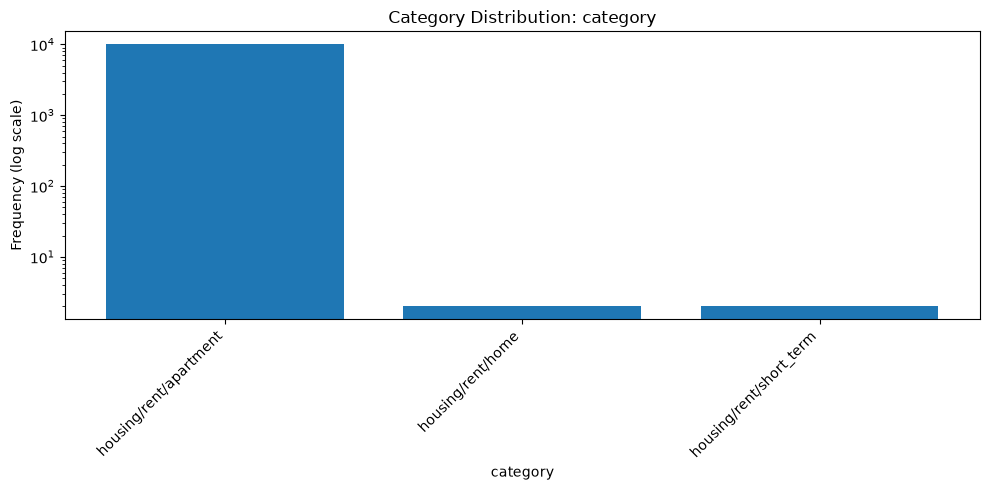

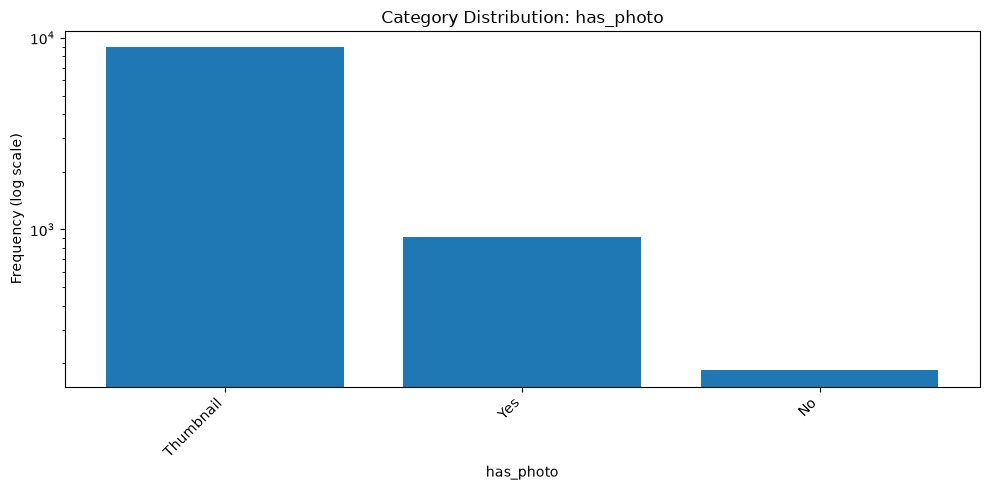

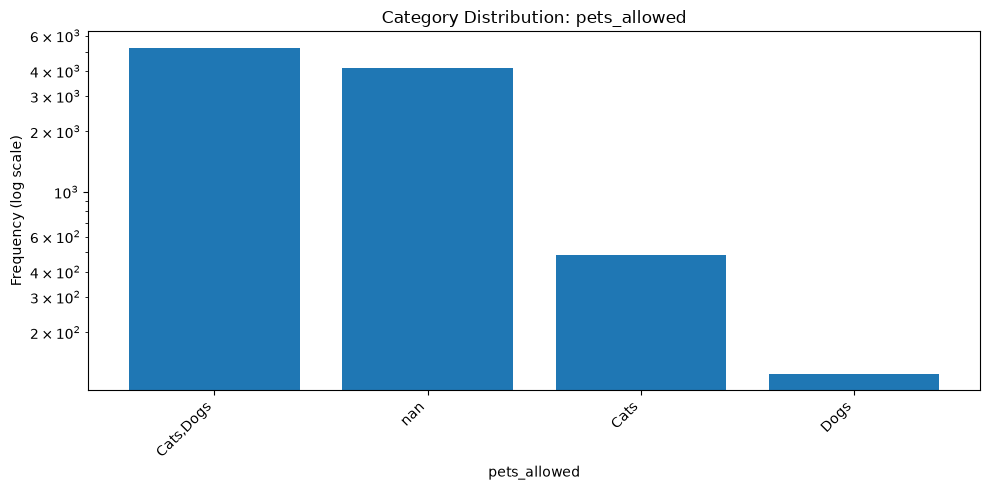

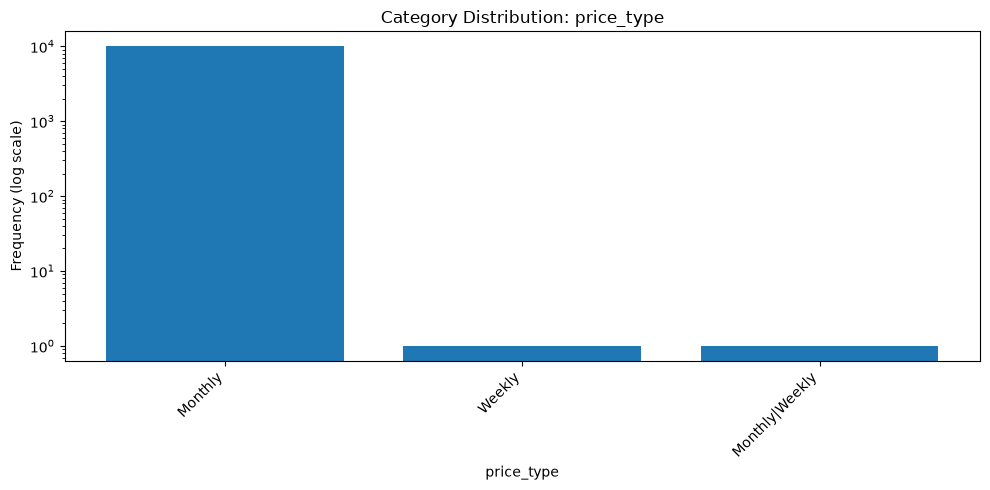

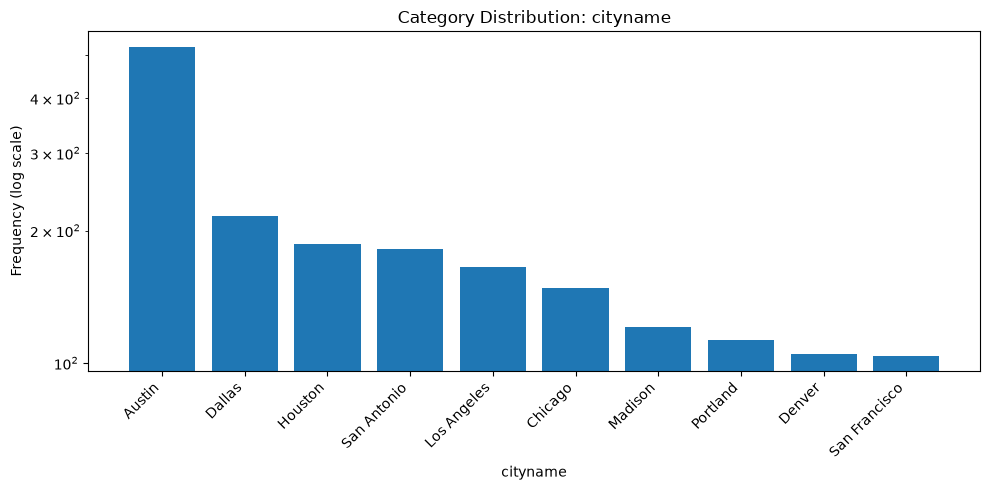

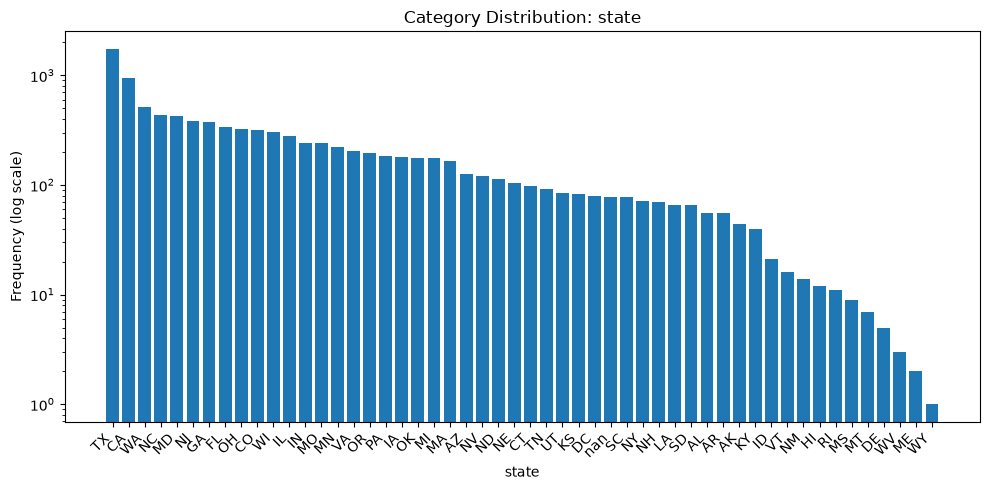

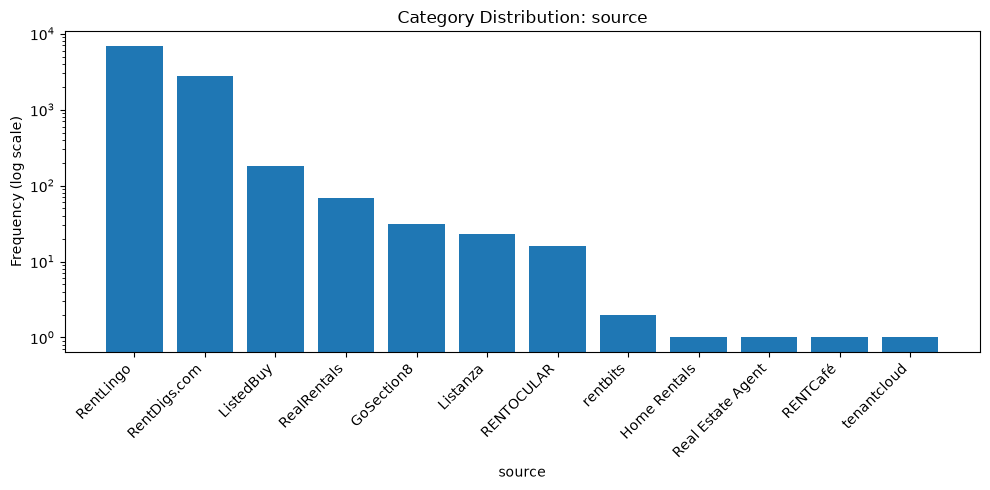

In [ ]:
# Paart 1: Bar Plots for Categorical Features
for feature in selected_categories:
    counts = apartments_df[feature].value_counts(dropna=False)
    if feature == 'cityname':
        counts = counts.head(10)
    labels = counts.index.map(str).tolist()
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.bar(range(len(labels)), counts.values)

    ax.set(
        title=f'Category Distribution: {feature}',
        xlabel=feature,
        ylabel='Frequency (log scale)',
        yscale='log'
    )

    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=45, ha='right')

    plt.tight_layout()
    plt.show()

# Summary:
# Bar plots show how frequently each category appears.
# The logarithmic scale helps compare categories with different frequencies.
# Only the 10 most common cities are displayed for readability.

In [ ]:
# Part 1: Derived Features and Analytics Base Table (ABT)
abt = apartments_df.copy()

abt['price_per_sqft'] = abt['price'] / abt['square_feet'].replace(0, np.nan)
abt['price_per_bedroom'] = abt['price'] / abt['bedrooms'].replace(0, np.nan)
abt['price_per_bathroom'] = abt['price'] / abt['bathrooms'].replace(0, np.nan)

# Missing info 
for col in ['amenities', 'pets_allowed', 'address']:
    abt[f'{col}_missing'] = abt[col].isna().astype(int)

display(abt.head())

# Summary:
# New ratio features describe rental prices relative to apartment characteristics.
# Missing-value indicators show whether specific listing details are unavailable.
# The ABT combines original and derived features for further analysis.

,id,category,title,body,amenities,bathrooms,bedrooms,currency,fee,has_photo,...,latitude,longitude,source,time,price_per_sqft,price_per_bedroom,price_per_bathroom,amenities_missing,pets_allowed_missing,address_missing
0,5668626895,housing/rent/apartment,"Studio apartment 2nd St NE, Uhland Terrace NE,...","This unit is located at second St NE, Uhland T...",NaN,NaN,0.0,USD,No,Thumbnail,...,38.9057,-76.9861,RentLingo,2019-12-26 11:23:35,7.821782,NaN,NaN,1,1,1
1,5664597177,housing/rent/apartment,Studio apartment 814 Schutte Road,"This unit is located at 814 Schutte Road, Evan...",NaN,NaN,1.0,USD,No,Thumbnail,...,37.9680,-87.6621,RentLingo,2019-12-22 12:17:43,4.009434,425.0,NaN,1,1,0
2,5668626833,housing/rent/apartment,"Studio apartment N Scott St, 14th St N, Arling...","This unit is located at N Scott St, 14th St N,...",NaN,1.0,0.0,USD,No,Thumbnail,...,38.8910,-77.0816,RentLingo,2019-12-26 11:23:30,12.990654,NaN,1390.0,1,1,1
3,5659918074,housing/rent/apartment,Studio apartment 1717 12th Ave,"This unit is located at 1717 12th Ave, Seattle...",NaN,1.0,0.0,USD,No,Thumbnail,...,47.6160,-122.3275,RentLingo,2019-12-18 11:15:43,7.974138,NaN,925.0,1,1,0
4,5668626759,housing/rent/apartment,"Studio apartment Washington Blvd, N Cleveland ...","This unit is located at Washington Blvd, N Cle...",NaN,NaN,0.0,USD,No,Thumbnail,...,38.8738,-77.1055,RentLingo,2019-12-26 11:23:21,7.040000,NaN,NaN,1,1,1


In [ ]:
# ONLY MAIN FEATURES FOR THE REPORT 
new_features = [
    'price_per_sqft',
    'price_per_bedroom',
    'price_per_bathroom',
    'amenities_missing',
    'pets_allowed_missing',
    'address_missing'
]

display(abt[new_features].head())

,price_per_sqft,price_per_bedroom,price_per_bathroom,amenities_missing,pets_allowed_missing,address_missing
0,7.821782,NaN,NaN,1,1,1
1,4.009434,425.0,NaN,1,1,0
2,12.990654,NaN,1390.0,1,1,1
3,7.974138,NaN,925.0,1,1,0
4,7.040000,NaN,NaN,1,1,1


In [ ]:
# Part 1: Data Preprocessing
preprocessed_df = apartments_df.copy()
# Duplicates are removed
duplicate_count = preprocessed_df.duplicated().sum()
print(f"Duplicate rows: {duplicate_count}")
preprocessed_df.drop_duplicates(inplace=True)

# missing vakues 
missing_report = pd.DataFrame({
    'Missing values': preprocessed_df.isna().sum(),
    'Missing %': preprocessed_df.isna().mean() * 100
})
display(missing_report.round(2))

# Remove columns with more than 60% missing values
remove_cols = missing_report.index[missing_report['Missing %'] > 60].tolist()
print("Removed features (>60% missing):", remove_cols)

preprocessed_df.drop(columns=remove_cols, inplace=True)

numeric_cols = [col for col in continuous_features if col in preprocessed_df.columns]
category_cols = [col for col in categorical_features if col in preprocessed_df.columns]

# insrtead of the missing values, the median or mode can be used
for col in numeric_cols:
    preprocessed_df[col] = preprocessed_df[col].fillna(preprocessed_df[col].median())

for col in category_cols:
    mode = preprocessed_df[col].mode(dropna=True)
    if not mode.empty:
        preprocessed_df[col] = preprocessed_df[col].fillna(mode.iloc[0])

cardinality = pd.DataFrame({
    'Data Type': preprocessed_df.dtypes.astype(str),
    'Cardinality': preprocessed_df.nunique(dropna=False)
})
display(cardinality.sort_values('Cardinality'))

constant_cols = cardinality.index[cardinality['Cardinality'] == 1].tolist()
print("Constant features removed:", constant_cols)

preprocessed_df.drop(columns=constant_cols, inplace=True)
numeric_cols = [col for col in numeric_cols if col in preprocessed_df.columns]

outlier_results = []

for col in numeric_cols:
    values = preprocessed_df[col]
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1

    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = ((values < lower) | (values > upper)).sum()

    outlier_results.append({
        'Feature': col,
        'Outlier count': count,
        'Outlier %': count / len(values) * 100
    })

display(pd.DataFrame(outlier_results).round(2))


for col in ['price', 'square_feet']:
    if col in preprocessed_df.columns:
        q1, q3 = preprocessed_df[col].quantile([0.25, 0.75])
        iqr = q3 - q1

        preprocessed_df[col] = preprocessed_df[col].clip(
            lower=q1 - 1.5 * iqr,
            upper=q3 + 1.5 * iqr
        )

print("\nOriginal shape:", apartments_df.shape)
print("Preprocessed shape:", preprocessed_df.shape)

Duplicate rows: 0


,Missing values,Missing %
id,0,0.00
category,0,0.00
title,0,0.00
body,0,0.00
amenities,3549,35.49
bathrooms,34,0.34
bedrooms,7,0.07
currency,0,0.00
fee,0,0.00
has_photo,0,0.00


Removed features (>60% missing): []


,Data Type,Cardinality
currency,str,1
fee,str,1
has_photo,str,3
category,str,3
price_type,str,3
pets_allowed,str,3
bedrooms,float64,10
source,str,12
bathrooms,float64,14
state,str,51


Constant features removed: ['currency', 'fee']


,Feature,Outlier count,Outlier %
0,bathrooms,72,0.72
1,bedrooms,514,5.14
2,price,618,6.18
3,square_feet,622,6.22
4,latitude,56,0.56
5,longitude,56,0.56



Original shape: (10000, 22)
Preprocessed shape: (10000, 20)


In [ ]:
# Part 2: Data Preparation for Machine Learning (The task a) KNN; b) Decision Tree; c) Random Forest)
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

target = 'price'
excluded_cols = [
    'price', 'id', 'time', 'datetime',
    'title', 'body', 'address', 'price_display'
]

X = preprocessed_df.drop(columns=excluded_cols, errors='ignore')
y = preprocessed_df[target]

num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(
    include=['object', 'string', 'category', 'bool']
).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

preprocessor = ColumnTransformer([
    ('numeric', StandardScaler(), num_cols),
    ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training data:", X_train.shape, "→", X_train_processed.shape)
print("Testing data:", X_test.shape, "→", X_test_processed.shape)

Training data: (8000, 13) → (8000, 3416)
Testing data: (2000, 13) → (2000, 3416)


In [ ]:
# Part 2: a)KNN algorithm
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

class CustomKNNRegressor:

    def __init__(self, k=5, batch_size=200):
        self.k = k
        self.batch_size = batch_size

    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype=np.float32)
        self.y_train = np.asarray(y, dtype=np.float32)

        if not 1 <= self.k <= len(self.X_train):
            raise ValueError("k must be between 1 and the training sample count.")

        self.train_norms = np.sum(self.X_train ** 2, axis=1)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=np.float32)
        predictions = np.empty(len(X))

        for start in range(0, len(X), self.batch_size):
            batch = X[start:start + self.batch_size]

            distances = (
                np.sum(batch ** 2, axis=1, keepdims=True)
                + self.train_norms
                - 2 * batch @ self.X_train.T
            )

            distances = np.maximum(distances, 0)

            neighbors = np.argpartition(
                distances, self.k - 1, axis=1
            )[:, :self.k]

            predictions[start:start + len(batch)] = (
                self.y_train[neighbors].mean(axis=1)
            )

        return predictions

knn_results = []

for k in [3, 5, 7, 9]:
    model = CustomKNNRegressor(k=k)
    model.fit(X_train_processed, y_train)

    predictions = model.predict(X_test_processed)

    knn_results.append({
        'Model': 'Custom KNN',
        'k': k,
        'MAE': mean_absolute_error(y_test, predictions),
        'MAPE (%)': np.mean(
            np.abs((y_test.to_numpy() - predictions) /
                   np.maximum(np.abs(y_test.to_numpy()), 1e-8))
        ) * 100,
        'RMSE': np.sqrt(mean_squared_error(y_test, predictions)),
        'R²': r2_score(y_test, predictions)
    })

knn_results = pd.DataFrame(knn_results)
display(knn_results.round(4))

,Model,k,MAE,MAPE (%),RMSE,R²
0,Custom KNN,3,222.1220,18.2387,314.9737,0.7196
1,Custom KNN,5,226.3204,18.5249,314.4920,0.7204
2,Custom KNN,7,228.8868,18.7894,314.8761,0.7197
3,Custom KNN,9,233.2095,19.1880,319.3855,0.7116


In [ ]:
# Part 2: a) Built-in KNN Regressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

built_in_knn_results = []

for k in [3, 5, 7, 9]:

    model = KNeighborsRegressor(
        n_neighbors=k,
        metric='euclidean',
        algorithm='brute',
        n_jobs=1
    )

    model.fit(X_train_processed, y_train)
    predictions = model.predict(X_test_processed)

    mae = mean_absolute_error(y_test, predictions)
    mape = np.mean(
        np.abs((y_test.to_numpy() - predictions) /
               np.maximum(np.abs(y_test.to_numpy()), 1e-8))
    ) * 100
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    built_in_knn_results.append({
        'Model': 'Built-in KNN',
        'k': k,
        'MAE': mae,
        'MAPE (%)': mape,
        'RMSE': rmse,
        'R²': r2
    })

built_in_knn_results = pd.DataFrame(built_in_knn_results)
display(built_in_knn_results.round(4))

,Model,k,MAE,MAPE (%),RMSE,R²
0,Built-in KNN,3,221.8117,18.2035,314.4954,0.7204
1,Built-in KNN,5,226.2099,18.5079,314.5805,0.7203
2,Built-in KNN,7,228.5725,18.7631,314.8203,0.7198
3,Built-in KNN,9,233.0268,19.1745,319.1598,0.7121


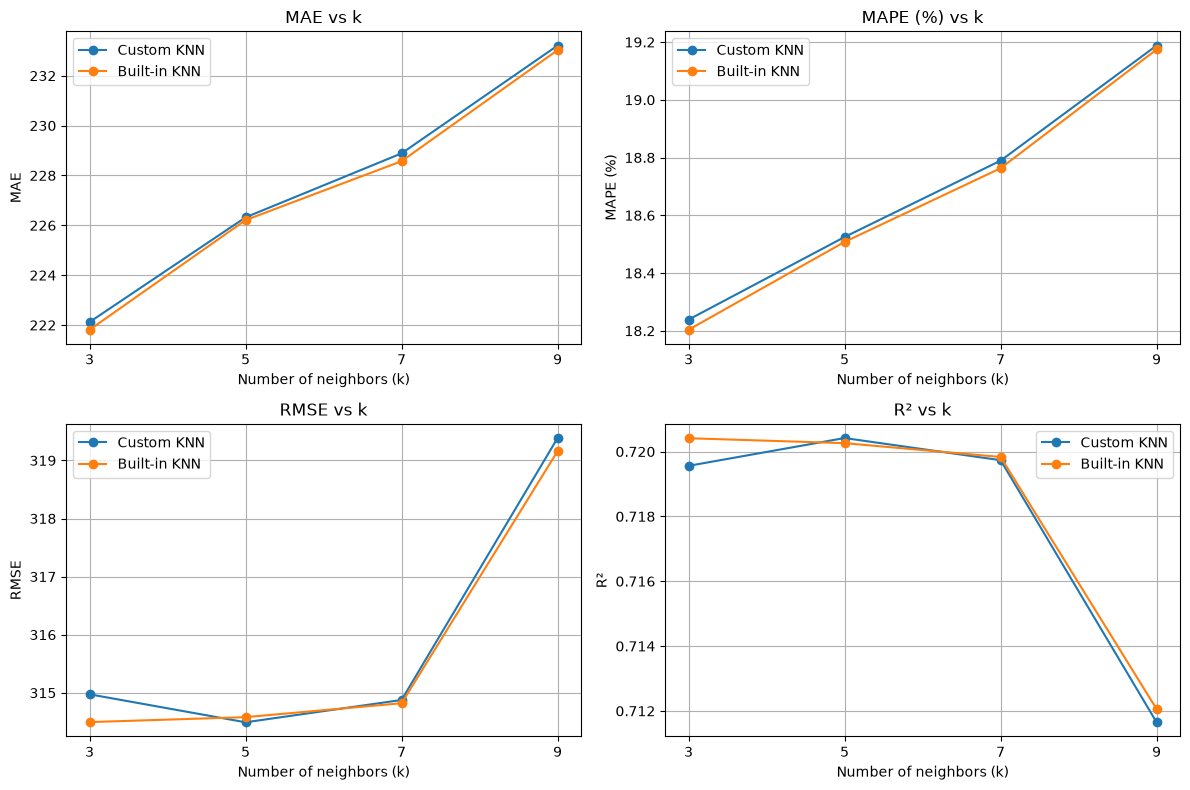

In [ ]:
# Part 2: a) KNN vs Built-in KNN
import matplotlib.pyplot as plt

knn_comparison = pd.concat([knn_results, built_in_knn_results], ignore_index=True)

metrics = ['MAE', 'MAPE (%)', 'RMSE', 'R²']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, metric in zip(axes.flatten(), metrics):
    for model in ['Custom KNN', 'Built-in KNN']:
        data = knn_comparison[knn_comparison['Model'] == model]

        ax.plot(data['k'], data[metric], marker='o', label=model)

    ax.set_title(f'{metric} vs k')
    ax.set_xlabel('Number of neighbors (k)')
    ax.set_ylabel(metric)
    ax.set_xticks([3, 5, 7, 9])
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Part 2:b)Prepare data for Decision Tree

from sklearn.model_selection import train_test_split

drop_cols = ['price', 'id', 'time', 'title', 'body', 'address', 'price_display']

X_tree = preprocessed_df.drop(columns=drop_cols, errors='ignore').copy()
y_tree = preprocessed_df['price']

if 'datetime' in X_tree.columns:
    X_tree['month'] = X_tree['datetime'].dt.month
    X_tree = X_tree.drop(columns='datetime')

num_features = X_tree.select_dtypes(include='number').columns.tolist()
cat_features = X_tree.select_dtypes(include=['object', 'string', 'category', 'bool']).columns.tolist()

X_tree_train, X_tree_test, y_tree_train, y_tree_test = train_test_split(
    X_tree, y_tree, test_size=0.2, random_state=42
)

for col in num_features:
    value = X_tree_train[col].median()
    X_tree_train[col] = X_tree_train[col].fillna(value)
    X_tree_test[col] = X_tree_test[col].fillna(value)

for col in cat_features:
    value = X_tree_train[col].mode().iloc[0]
    X_tree_train[col] = X_tree_train[col].fillna(value)
    X_tree_test[col] = X_tree_test[col].fillna(value)

In [ ]:
# Part 2:b) Custom Decision Tree Regressor

import numpy as np

class CustomDecisionTreeRegressor:

    def __init__(self, max_depth=5, min_samples_leaf=10):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
    # start training 
    def fit(self, X, y, num_features, cat_features):
        self.num_features = num_features
        self.cat_features = cat_features
        self.tree = self.build(X.reset_index(drop=True),
                               np.asarray(y), 0)
        return self

    def mse(self, y):
        return np.mean((y - np.mean(y)) ** 2)
    # Initialize the search for the best split
    def best_split(self, X, y):
        best_gain = 0
        best = None
        parent_mse = self.mse(y)

        # Numerical features: two branches
        for col in self.num_features:
            values = np.unique(X[col])

            if len(values) > 50:
                values = np.quantile(values, np.linspace(0, 1, 50))

            for threshold in (values[:-1] + values[1:]) / 2:
                left = X[col] <= threshold
                right = ~left

                if min(left.sum(), right.sum()) < self.min_samples_leaf:
                    continue

                error = (left.sum() * self.mse(y[left]) +
                         right.sum() * self.mse(y[right])) / len(y)

                gain = parent_mse - error

                if gain > best_gain:
                    best_gain = gain
                    best = ('num', col, threshold)

        # Categorical features: one branch per category
        for col in self.cat_features:
            groups = X[col].unique()

            if len(groups) < 2:
                continue

            masks = [X[col] == category for category in groups]

            if any(mask.sum() < self.min_samples_leaf for mask in masks):
                continue

            error = sum(mask.sum() * self.mse(y[mask])
                        for mask in masks) / len(y)

            gain = parent_mse - error

            if gain > best_gain:
                best_gain = gain
                best = ('cat', col, groups)

        return best

    def build(self, X, y, depth):
        prediction = np.mean(y)

        if (depth >= self.max_depth or
            len(y) < 2 * self.min_samples_leaf or
            self.mse(y) == 0):
            return {'prediction': prediction}

        split = self.best_split(X, y)

        if split is None:
            return {'prediction': prediction}

        kind, col, value = split

        if kind == 'num':
            left = X[col] <= value

            return {
                'kind': 'num', 'col': col, 'value': value,
                'left': self.build(X[left], y[left], depth + 1),
                'right': self.build(X[~left], y[~left], depth + 1)
            }

        branches = {}

        for category in value:
            mask = X[col] == category
            branches[category] = self.build(
                X[mask], y[mask], depth + 1
            )

        return {
            'kind': 'cat', 'col': col,
            'branches': branches,
            'prediction': prediction
        }

    def predict_one(self, row, node):
        if 'kind' not in node:
            return node['prediction']

        col = node['col']

        if node['kind'] == 'num':
            branch = 'left' if row[col] <= node['value'] else 'right'
            return self.predict_one(row, node[branch])

        category = row[col]
        if category in node['branches']:
            return self.predict_one(row, node['branches'][category])

        return node['prediction']

    def predict(self, X):
        return np.array([
            self.predict_one(row, self.tree)
            for _, row in X.iterrows()
        ])

In [ ]:
# Part 2:b) Evaluate Custom Decision Tree

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd

tree_configs = [(3, 10), (5, 10), (7, 10), (5, 20), (7, 20)]
tree_results = []

for depth, leaf in tree_configs:
    model = CustomDecisionTreeRegressor(
        max_depth=depth,
        min_samples_leaf=leaf
    )

    model.fit(X_tree_train, y_tree_train, num_features, cat_features)
    predictions = model.predict(X_tree_test)

    actual = y_tree_test.to_numpy()

    tree_results.append({
        'Model': 'Custom Decision Tree',
        'max_depth': depth,
        'min_samples_leaf': leaf,
        'MAE': mean_absolute_error(actual, predictions),
        'MAPE (%)': np.mean(np.abs((actual - predictions) /
                                 np.maximum(np.abs(actual), 1e-8))) * 100,
        'RMSE': np.sqrt(mean_squared_error(actual, predictions)),
        'R²': r2_score(actual, predictions)
    })

tree_results = pd.DataFrame(tree_results)
display(tree_results.round(4))

,Model,max_depth,min_samples_leaf,MAE,MAPE (%),RMSE,R²
0,Custom Decision Tree,3,10,320.4893,26.5389,412.6609,0.5186
1,Custom Decision Tree,5,10,293.1331,24.1740,384.9856,0.5810
2,Custom Decision Tree,7,10,259.7462,21.4542,349.1980,0.6553
3,Custom Decision Tree,5,20,293.7371,24.1871,385.3135,0.5803
4,Custom Decision Tree,7,20,267.4779,22.0078,357.9831,0.6377


In [ ]:
# Part 2:b)Built-in Decision Tree Regressor

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


tree_preprocessor = ColumnTransformer([
    ('num', 'passthrough', num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
])

X_train_encoded = tree_preprocessor.fit_transform(X_tree_train)
X_test_encoded = tree_preprocessor.transform(X_tree_test)


tree_configs = [(3, 10), (5, 10), (7, 10), (5, 20), (7, 20)]
built_in_tree_results = []

for depth, leaf in tree_configs:

    model = DecisionTreeRegressor(
        max_depth=depth,
        min_samples_leaf=leaf,
        random_state=42
    )

    model.fit(X_train_encoded, y_tree_train)
    predictions = model.predict(X_test_encoded)

    actual = y_tree_test.to_numpy()

    built_in_tree_results.append({
        'Model': 'Built-in Decision Tree',
        'max_depth': depth,
        'min_samples_leaf': leaf,
        'MAE': mean_absolute_error(actual, predictions),
        'MAPE (%)': np.mean(np.abs((actual - predictions) /
                                  np.maximum(np.abs(actual), 1e-8))) * 100,
        'RMSE': np.sqrt(mean_squared_error(actual, predictions)),
        'R²': r2_score(actual, predictions)
    })

built_in_tree_results = pd.DataFrame(built_in_tree_results)
display(built_in_tree_results.round(4))

,Model,max_depth,min_samples_leaf,MAE,MAPE (%),RMSE,R²
0,Built-in Decision Tree,3,10,333.3976,27.8572,428.2487,0.4816
1,Built-in Decision Tree,5,10,292.2531,24.3995,387.5247,0.5755
2,Built-in Decision Tree,7,10,272.0810,22.7019,363.0482,0.6274
3,Built-in Decision Tree,5,20,292.3358,24.3800,386.8618,0.5769
4,Built-in Decision Tree,7,20,275.4764,22.8464,367.6653,0.6179


In [ ]:
# Part 2:c) Built-in Random Forest Regressor

from sklearn.ensemble import RandomForestRegressor

# (number of trees, maximum depth, minimum samples per leaf)
rf_configs = [
    (50, 5, 5),
    (100, 5, 5),
    (100, 10, 5),
    (100, 15, 5),
    (100, 10, 10),
    (200, 10, 5)
]

rf_results = []

for trees, depth, leaf in rf_configs:

    model = RandomForestRegressor(
        n_estimators=trees,
        max_depth=depth,
        min_samples_leaf=leaf,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_encoded, y_tree_train)
    predictions = model.predict(X_test_encoded)

    actual = y_tree_test.to_numpy()

    rf_results.append({
        'Model': 'Random Forest',
        'n_estimators': trees,
        'max_depth': depth,
        'min_samples_leaf': leaf,
        'MAE': mean_absolute_error(actual, predictions),
        'MAPE (%)': np.mean(np.abs((actual - predictions) /
                                  np.maximum(np.abs(actual), 1e-8))) * 100,
        'RMSE': np.sqrt(mean_squared_error(actual, predictions)),
        'R²': r2_score(actual, predictions)
    })

rf_results = pd.DataFrame(rf_results)
display(rf_results.round(4))

,Model,n_estimators,max_depth,min_samples_leaf,MAE,MAPE (%),RMSE,R²
0,Random Forest,50,5,5,279.8209,23.6704,364.3401,0.6248
1,Random Forest,100,5,5,279.8857,23.6636,364.6469,0.6241
2,Random Forest,100,10,5,227.8525,19.1460,308.7350,0.7306
3,Random Forest,100,15,5,209.2731,17.2967,290.6939,0.7611
4,Random Forest,100,10,10,233.3364,19.4726,315.1007,0.7193
5,Random Forest,200,10,5,228.0739,19.1557,309.0252,0.7301


,Model,k,MAE,MAPE (%),RMSE,R²,max_depth,min_samples_leaf,n_estimators
0,Custom KNN,3.0,222.1220,18.2387,314.9737,0.7196,NaN,NaN,NaN
1,Custom KNN,5.0,226.3204,18.5249,314.4920,0.7204,NaN,NaN,NaN
2,Custom KNN,7.0,228.8868,18.7894,314.8761,0.7197,NaN,NaN,NaN
3,Custom KNN,9.0,233.2095,19.1880,319.3855,0.7116,NaN,NaN,NaN
4,Built-in KNN,3.0,221.8117,18.2035,314.4954,0.7204,NaN,NaN,NaN
5,Built-in KNN,5.0,226.2099,18.5079,314.5805,0.7203,NaN,NaN,NaN
6,Built-in KNN,7.0,228.5725,18.7631,314.8203,0.7198,NaN,NaN,NaN
7,Built-in KNN,9.0,233.0268,19.1745,319.1598,0.7121,NaN,NaN,NaN
8,Custom Decision Tree,NaN,320.4893,26.5389,412.6609,0.5186,3.0,10.0,NaN
9,Custom Decision Tree,NaN,293.1331,24.1740,384.9856,0.5810,5.0,10.0,NaN


Best configuration for each model:


,Model,k,MAE,MAPE (%),RMSE,R²,max_depth,min_samples_leaf,n_estimators
15,Built-in Decision Tree,NaN,272.0810,22.7019,363.0482,0.6274,7.0,10.0,NaN
4,Built-in KNN,3.0,221.8117,18.2035,314.4954,0.7204,NaN,NaN,NaN
10,Custom Decision Tree,NaN,259.7462,21.4542,349.1980,0.6553,7.0,10.0,NaN
1,Custom KNN,5.0,226.3204,18.5249,314.4920,0.7204,NaN,NaN,NaN
21,Random Forest,NaN,209.2731,17.2967,290.6939,0.7611,15.0,5.0,100.0


,Model,MAE,MAPE (%),RMSE,R²
21,Random Forest,209.2731,17.2967,290.6939,0.7611
1,Custom KNN,226.3204,18.5249,314.4920,0.7204
4,Built-in KNN,221.8117,18.2035,314.4954,0.7204
10,Custom Decision Tree,259.7462,21.4542,349.1980,0.6553
15,Built-in Decision Tree,272.0810,22.7019,363.0482,0.6274


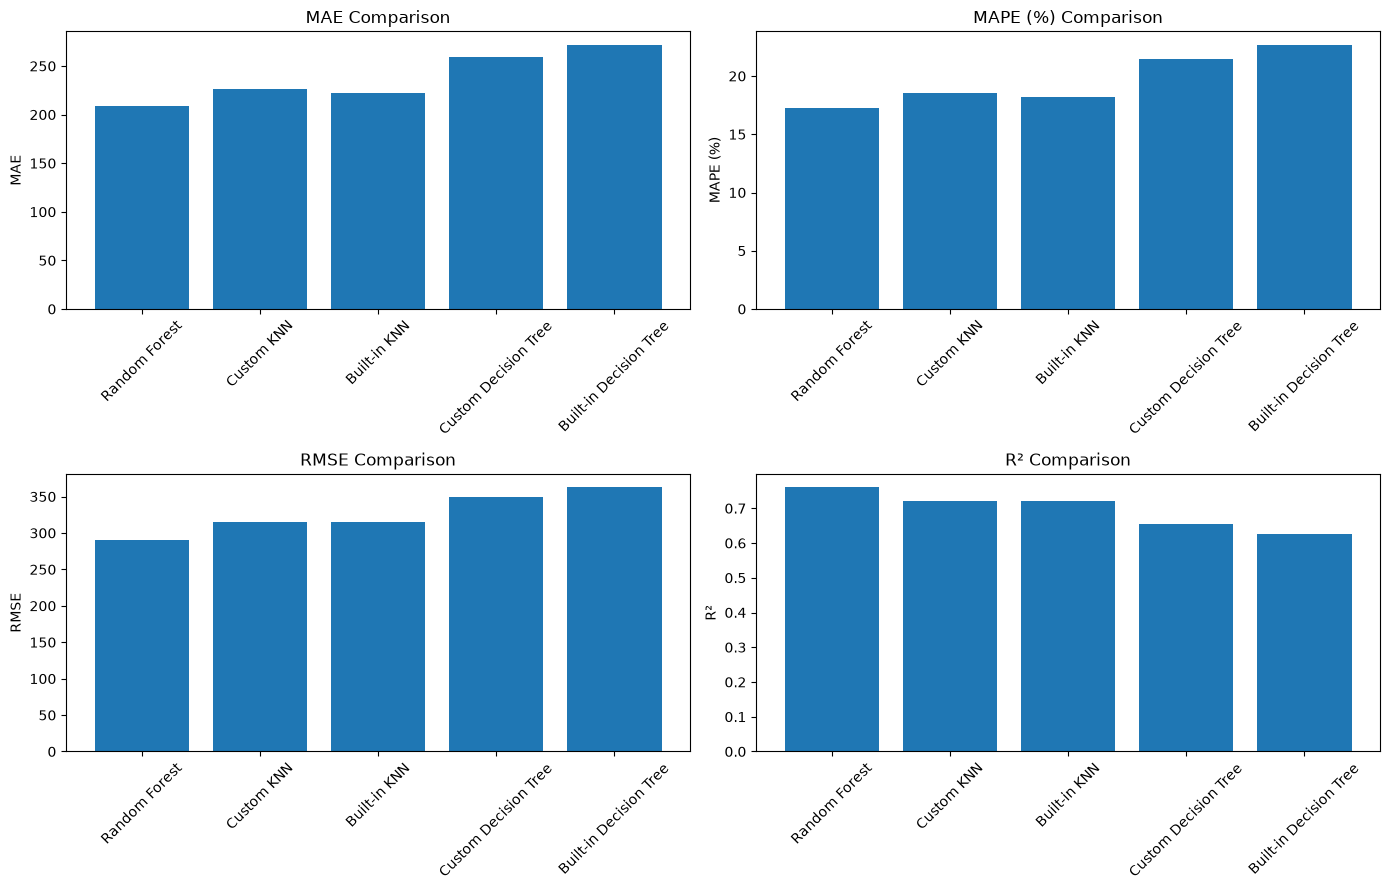

In [ ]:
# Part 3 Overall Model Comparison

import pandas as pd
import matplotlib.pyplot as plt

# Combine results from all five models
all_results = pd.concat([
    knn_results,
    built_in_knn_results,
    tree_results,
    built_in_tree_results,
    rf_results
], ignore_index=True)

display(all_results.round(4))

# Select the best configuration of each model using R²
best_results = all_results.loc[
    all_results.groupby('Model')['R²'].idxmax()
]

print("Best configuration for each model:")
display(best_results.round(4))

# Compare models from highest to lowest R²
metrics = ['MAE', 'MAPE (%)', 'RMSE', 'R²']

comparison = best_results[['Model'] + metrics].sort_values(
    'R²', ascending=False
)

display(comparison.round(4))

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, metric in zip(axes.flatten(), metrics):
    ax.bar(comparison['Model'], comparison[metric])
    ax.set_title(f'{metric} Comparison')
    ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()
